# 08b — Model evaluation: where the candidate went wrong

This notebook is deliberately separate from the runnable submission pipeline. It loads the candidate produced by `08_run_pipeline.ipynb`, joins the supplied public labels only for evaluation, ranks contiguous disagreement intervals, and renders the observations around every disagreement.

The public labels are never fed back into feature construction or prediction. The plots are an error-analysis aid for deciding which observation or transition hypothesis needs improvement.

In [1]:
from pathlib import Path
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd().resolve()
if not (ROOT / 'possession_lab').exists() and (ROOT.parent / 'possession_lab').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
DATA_ROOT = ROOT / 'data'
BEST_OUTPUT = ROOT / 'evaluation' / 'results' / 'diagnostic_visible_ball_low_motion_dead_ball.csv'
GROUND_TRUTH = ROOT / 'evaluation' / 'gt' / 'BAR-ATH_possession_gt_public.csv'
if not BEST_OUTPUT.exists():
    raise FileNotFoundError(f'Run 08_run_pipeline.ipynb first; candidate is missing: {BEST_OUTPUT}')
os.environ['MTAH_DATA_DIR'] = str(DATA_ROOT)
print(f'candidate: {BEST_OUTPUT}')
print(f'public labels: {GROUND_TRUTH}')

candidate: /Users/luke/Desktop/barca-hack-repo-staging/evaluation/results/diagnostic_visible_ball_low_motion_dead_ball.csv
public labels: /Users/luke/Desktop/barca-hack-repo-staging/evaluation/gt/BAR-ATH_possession_gt_public.csv


## Disagreement intervals

A disagreement is an observed public frame where the candidate label differs from the public label. Adjacent disagreement frames are grouped into one interval so that a transition error is not counted as dozens of unrelated frame errors. The table is ranked by interval duration.

In [2]:
from possession_lab.calculations.features import build_engineered_features
from possession_lab.baseline_pipeline import ClosestTeamRuleModel
from possession_lab.temporal_rules import load_rules

# Rebuild observations for plotting only; the public labels enter after this table exists.
plot_features = build_engineered_features(model=ClosestTeamRuleModel(), rules=load_rules())
ground_truth = pd.read_csv(GROUND_TRUTH)
prediction = pd.read_csv(BEST_OUTPUT)
gt_by_frame = pd.Series(ground_truth['label'].astype(str).str.upper().to_numpy(), index=ground_truth['frame'].astype(int))
pred_by_frame = pd.Series(prediction['label'].astype(str).str.upper().to_numpy(), index=prediction['frame'].astype(int))
graded_mismatch = (gt_by_frame != 'X') & gt_by_frame.notna() & pred_by_frame.notna() & gt_by_frame.ne(pred_by_frame)
mismatch_frames = graded_mismatch[graded_mismatch].index.to_numpy(dtype=int)
if len(mismatch_frames) == 0:
    mismatch_windows = []
    window_table = pd.DataFrame(columns=['start_frame', 'end_frame', 'duration_frames', 'duration_s'])
    print('No public disagreement windows found.')
else:
    groups = np.split(mismatch_frames, np.where(np.diff(mismatch_frames) > 1)[0] + 1)
    mismatch_windows = sorted(((int(group[0]), int(group[-1])) for group in groups), key=lambda pair: pair[1] - pair[0], reverse=True)
    window_table = pd.DataFrame(mismatch_windows, columns=['start_frame', 'end_frame'])
    window_table['duration_frames'] = window_table['end_frame'] - window_table['start_frame'] + 1
    window_table['duration_s'] = window_table['duration_frames'] / 25.0
    display(window_table)
    print(f'public disagreement windows: {len(window_table)}; wrong graded frames: {len(mismatch_frames)}')

,start_frame,end_frame,duration_frames,duration_s
0,17293,17455,163,6.52
1,11351,11497,147,5.88
2,15656,15761,106,4.24
3,15889,15993,105,4.20
4,11553,11623,71,2.84
5,12805,12850,46,1.84
6,13785,13825,41,1.64
7,15766,15798,33,1.32
8,14846,14875,30,1.20
9,13680,13703,24,0.96


public disagreement windows: 17; wrong graded frames: 846


## Where the model went wrong

The loop below renders every disagreement window with context. The timeline compares candidate and public labels while retaining scenario and anchor observations. The final four-panel plot adds distance margin, nearest-player distance and closing effort, ball speed/acceleration, and kick-episode distance for the longest interval. Grey shading marks unavailable grading; orange shading marks missing-ball observations.

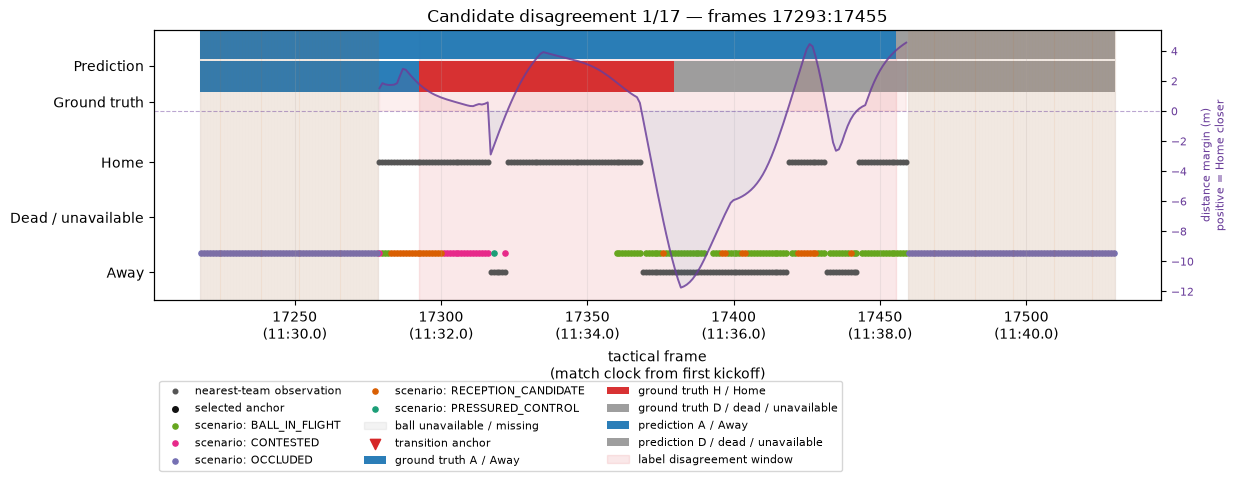

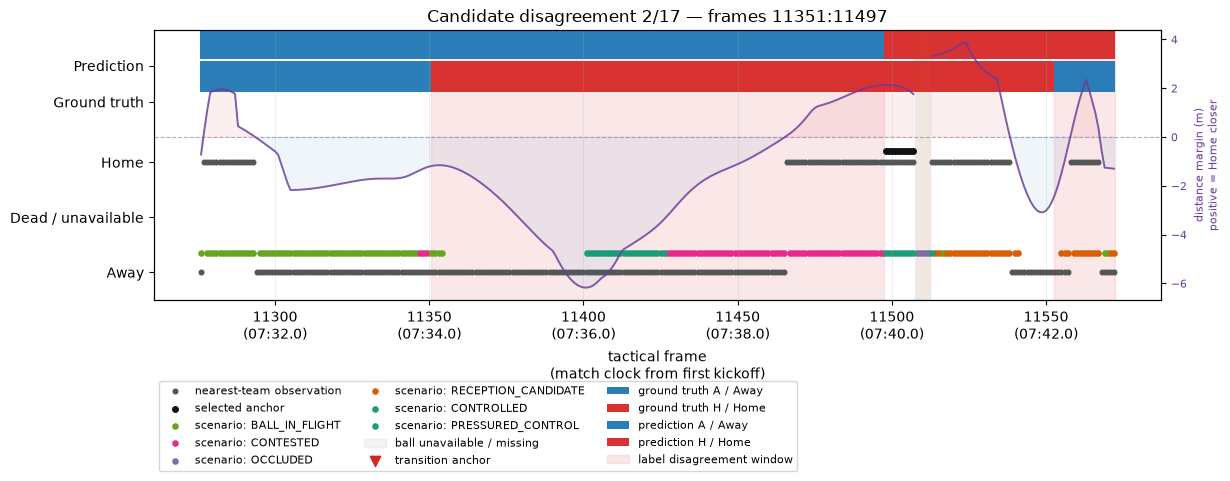

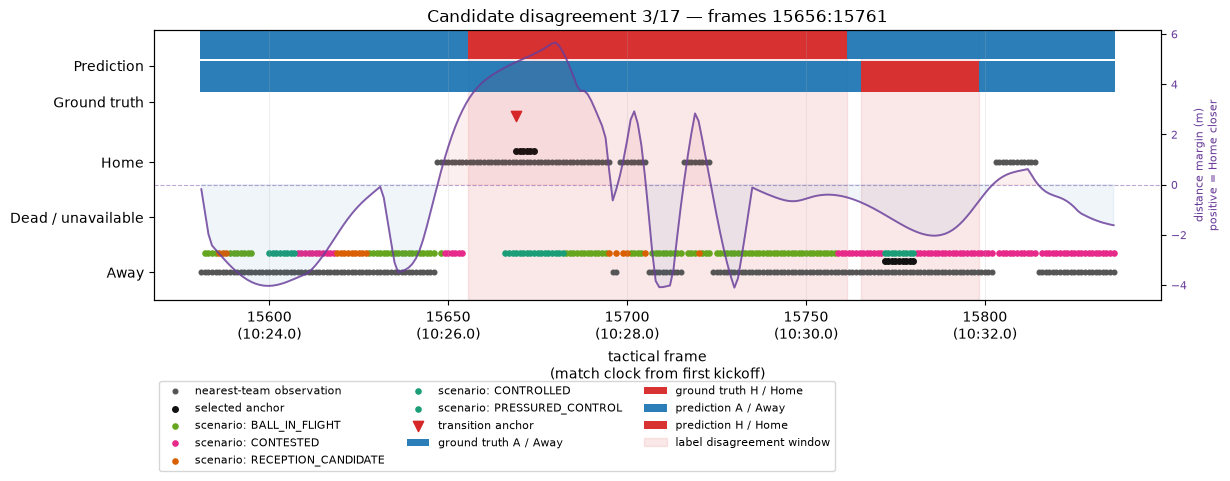

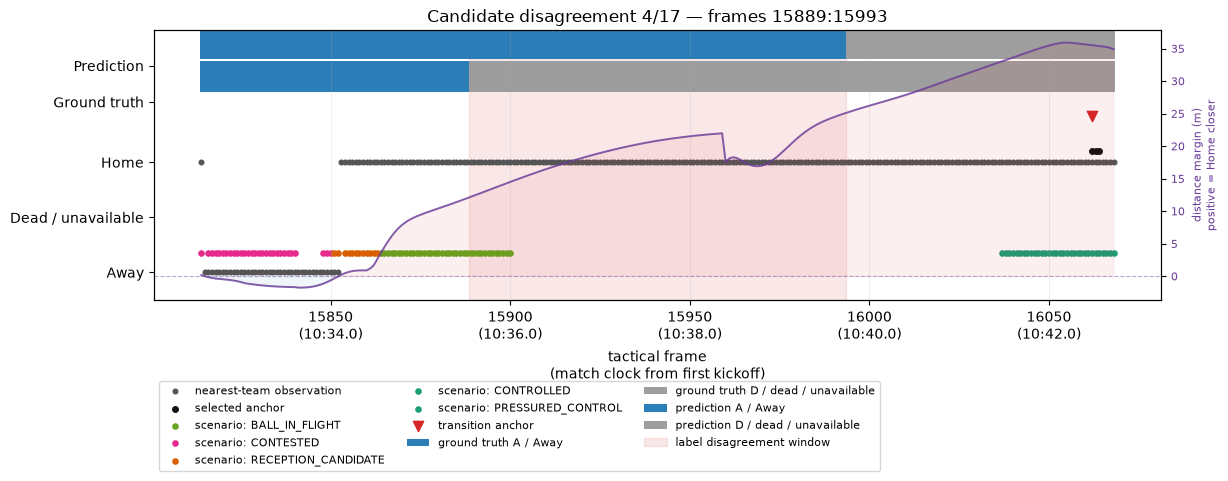

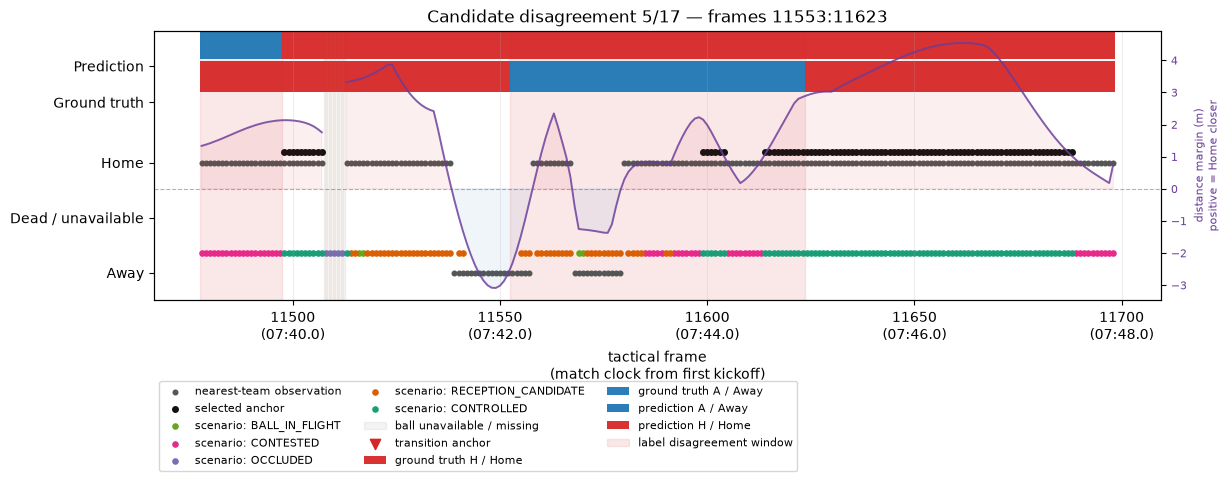

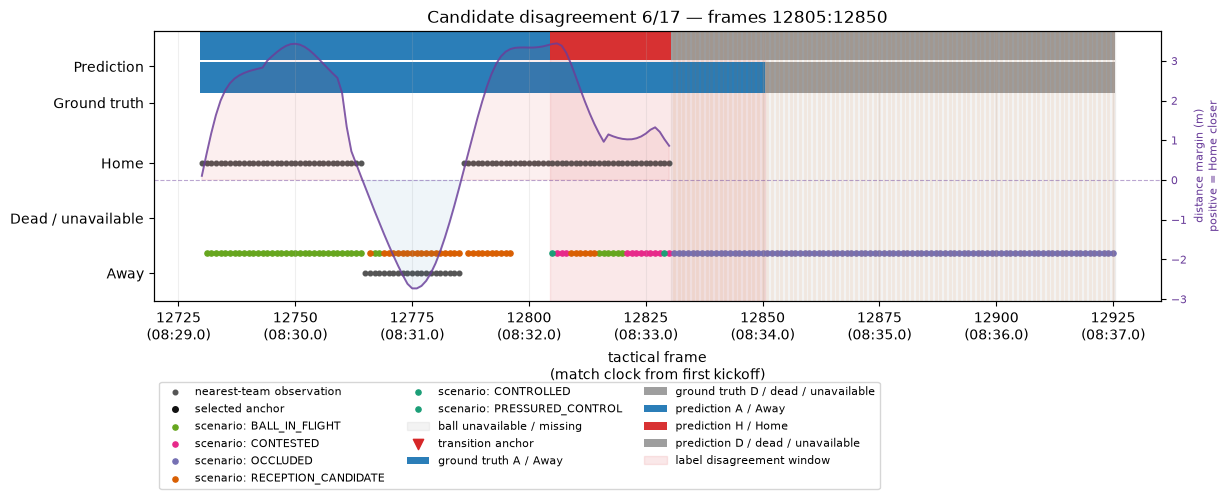

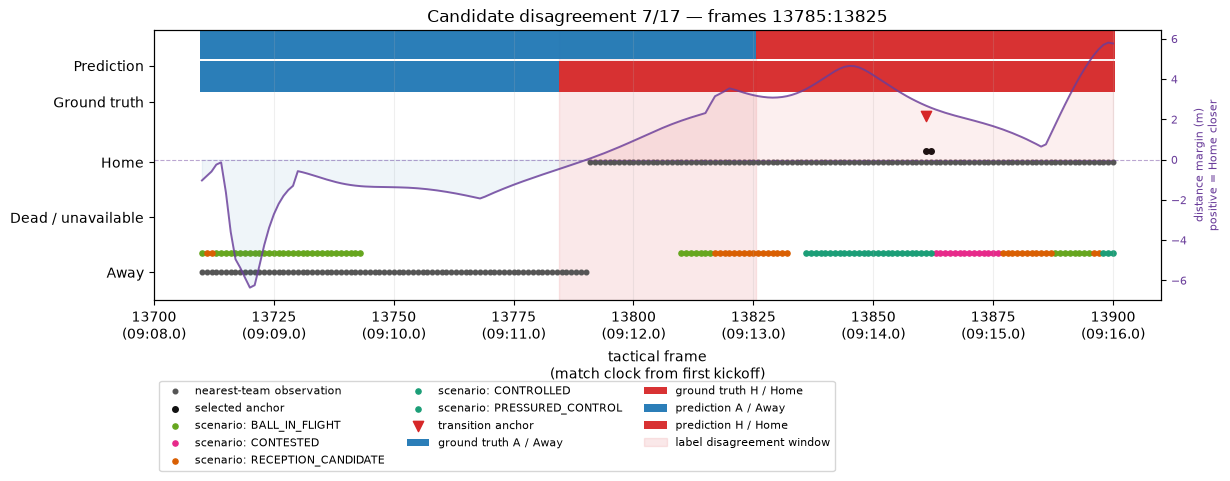

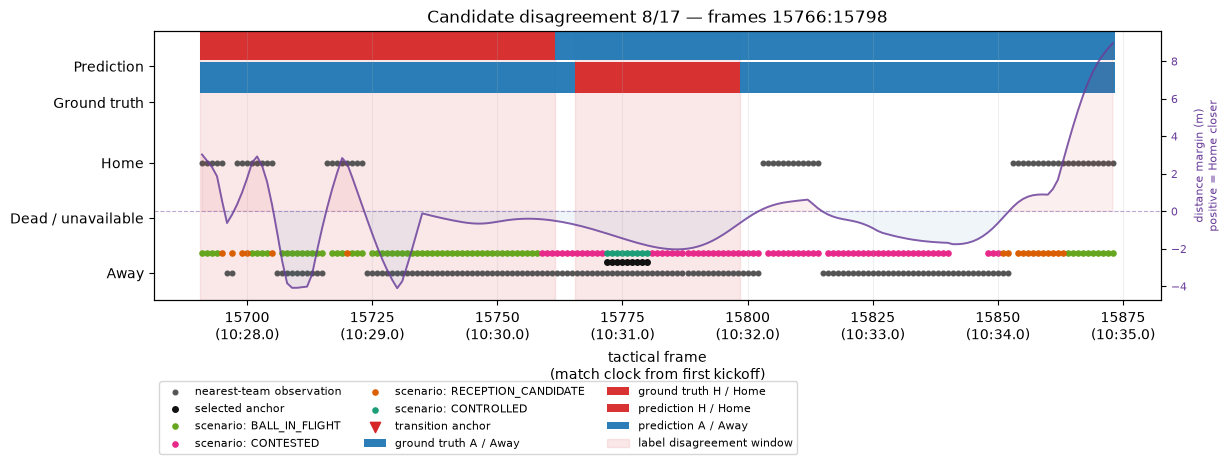

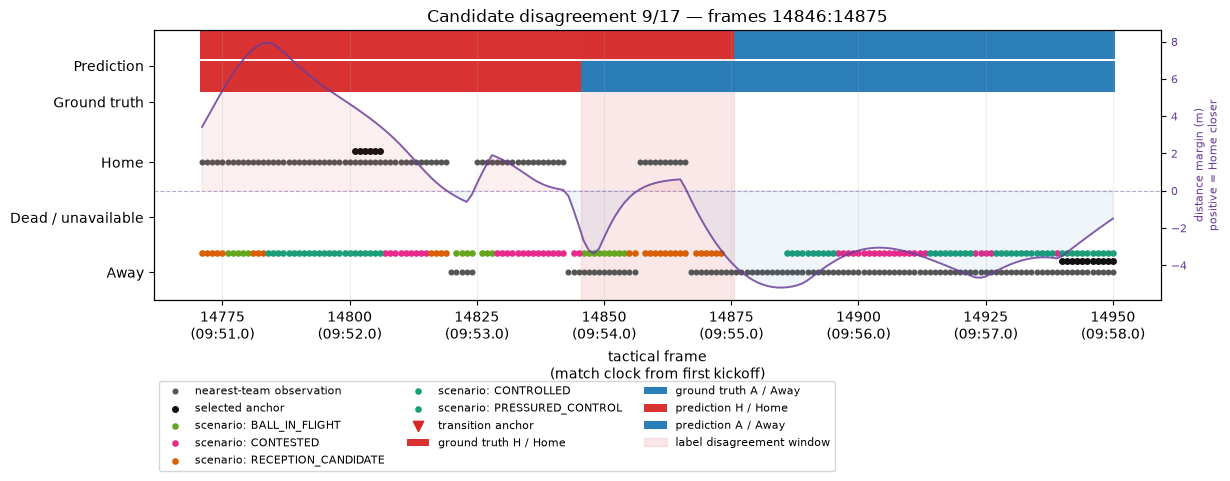

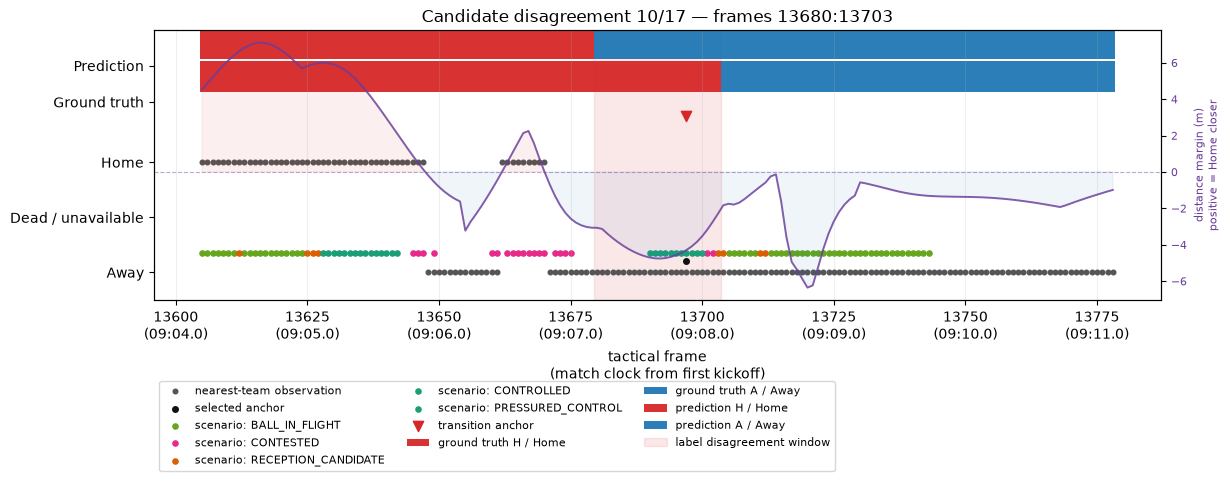

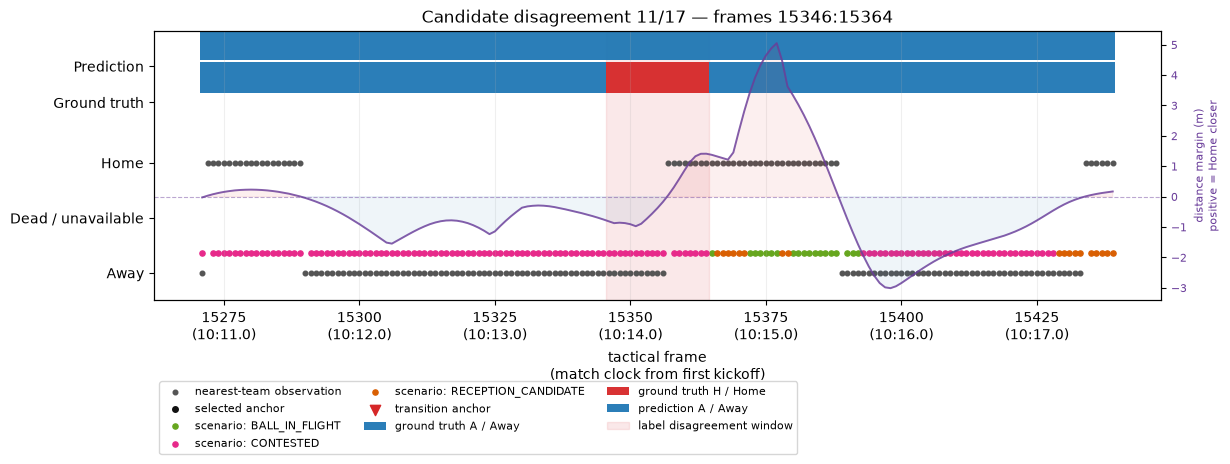

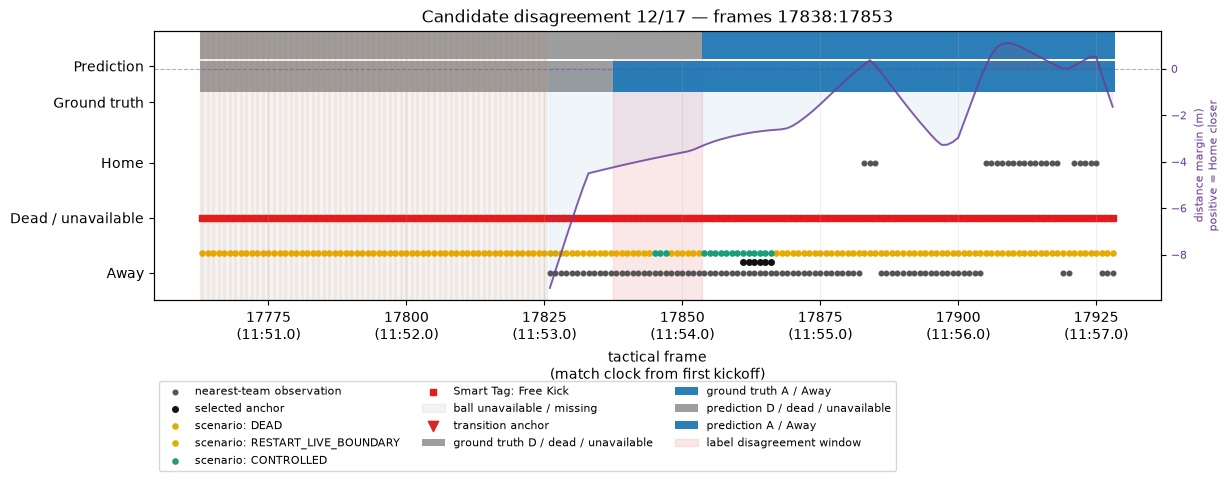

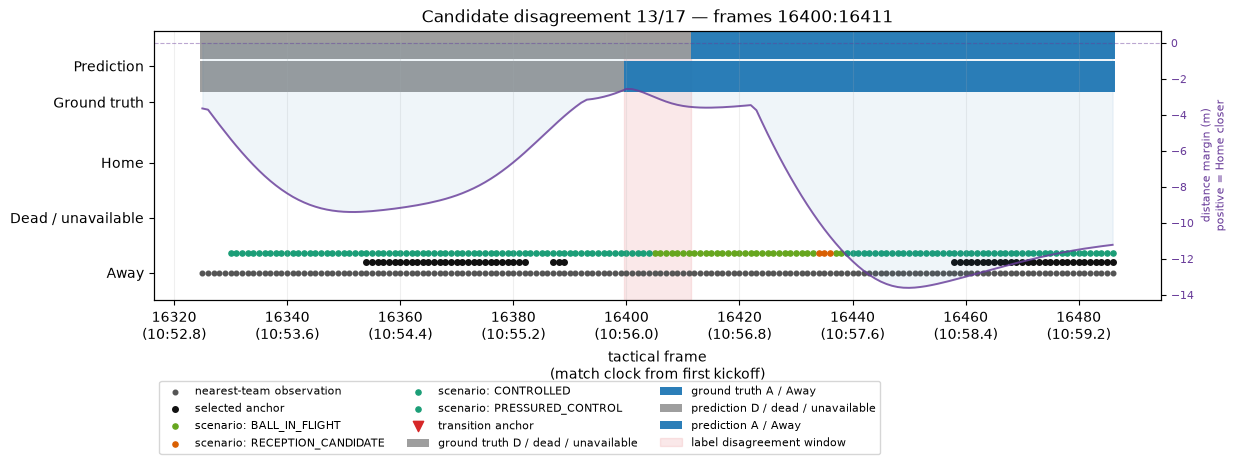

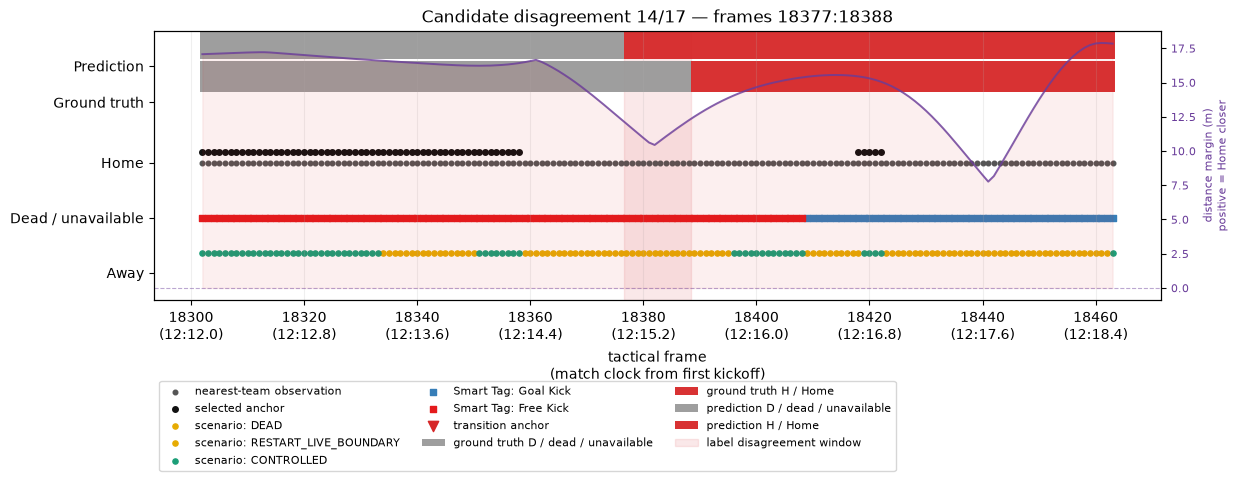

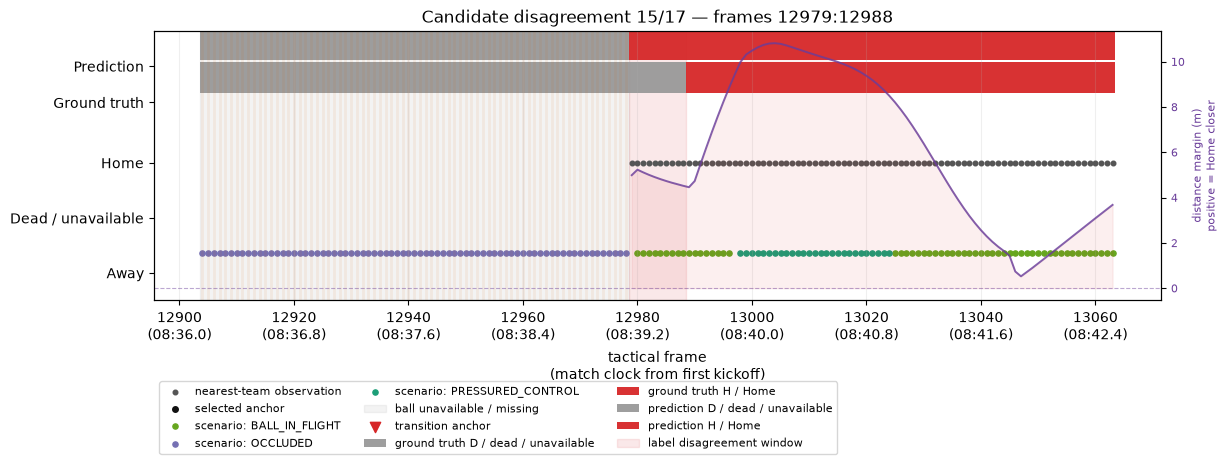

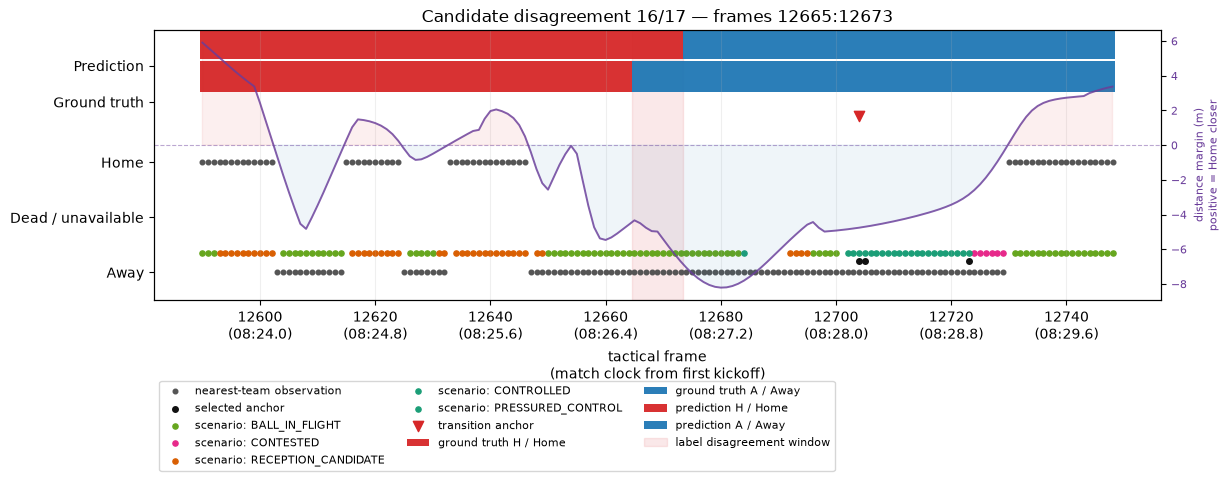

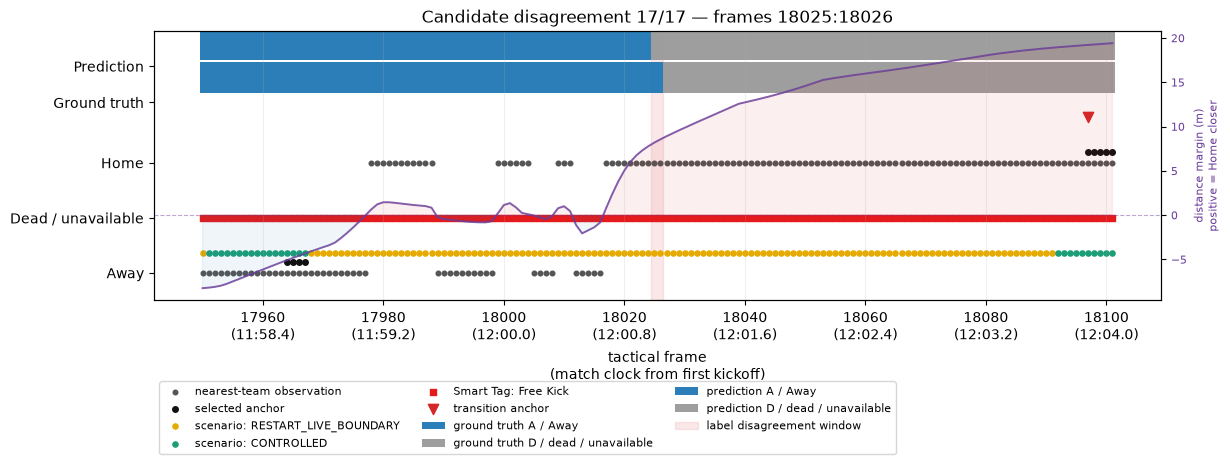

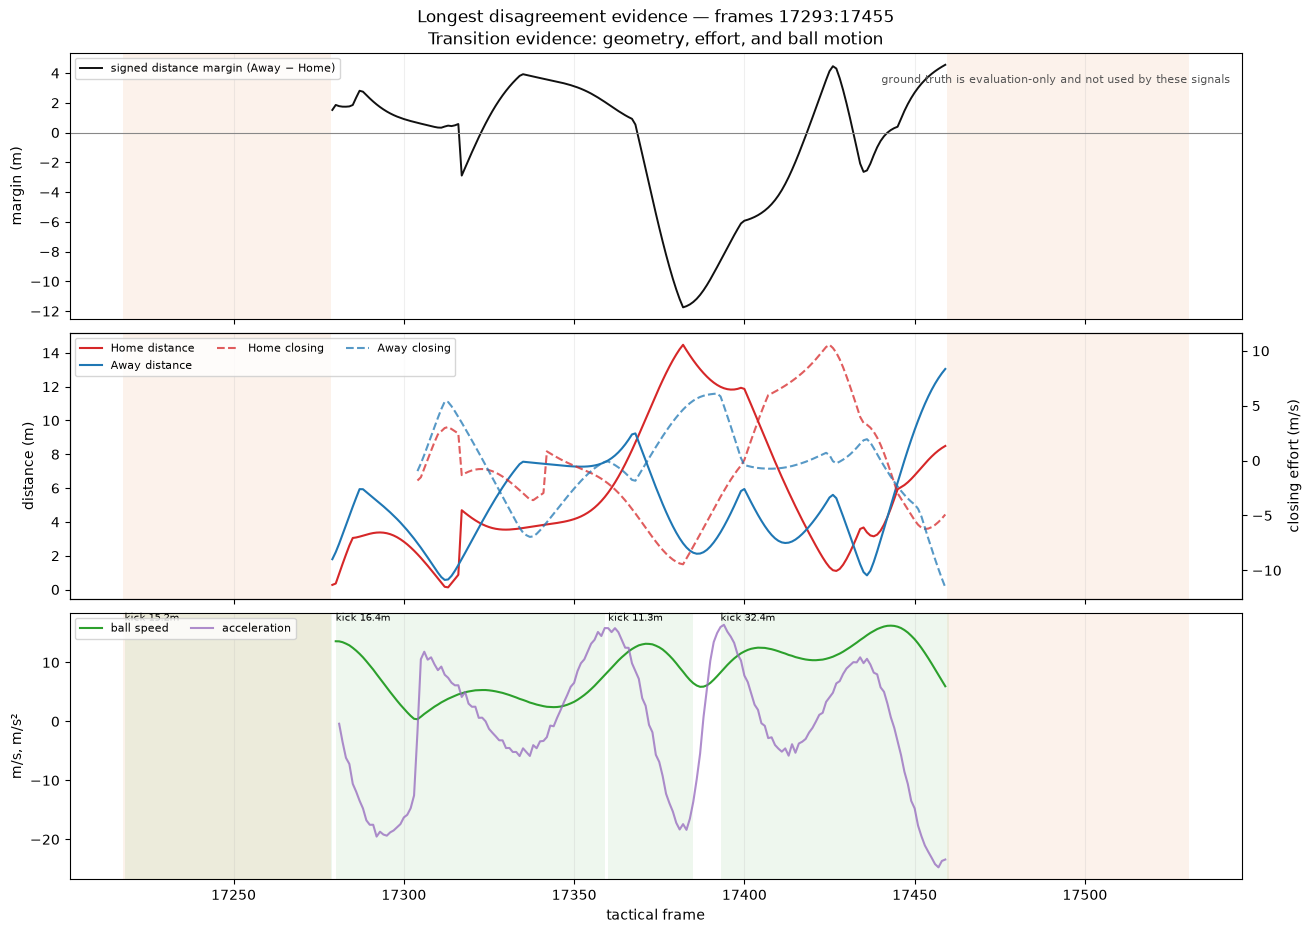

In [3]:
from possession.calculations.plotting import plot_timeline_window
from possession_lab.calculations.plotting import plot_transition_signals_window

context_frames = 75
for number, (window_start, window_end) in enumerate(mismatch_windows, start=1):
    left = max(int(plot_features['frame'].min()), window_start - context_frames)
    right = min(int(plot_features['frame'].max()), window_end + context_frames)
    figure, axis = plot_timeline_window(plot_features, left, right, ground_truth=gt_by_frame, predicted_labels=pred_by_frame)
    axis.set_title(f'Candidate disagreement {number}/{len(mismatch_windows)} — frames {window_start}:{window_end}')
    plt.show()

if mismatch_windows:
    window_start, window_end = mismatch_windows[0]
    left = max(int(plot_features['frame'].min()), window_start - context_frames)
    right = min(int(plot_features['frame'].max()), window_end + context_frames)
    figure, axes = plot_transition_signals_window(plot_features, left, right, ground_truth=gt_by_frame)
    figure.suptitle(f'Longest disagreement evidence — frames {window_start}:{window_end}', y=1.02)
    plt.show()

## Interpretation

These plots are diagnostic, not training data. Read each interval as: observations → scenario evidence → transition/no-switch hypotheses → resolved label. A disagreement is evidence that this chain needs review; it is not permission to overwrite the candidate using the public label.